# ETL standardization audit

Diff each dataset's stage-B (canonical, pre-standardization) GMT against its stage-C
(post-standardization) GMT to show what `filter_to_human_pc` actually does to the data:
renames (alias → current NCBI gene_info.gz's Symbol column, uppercased via NCBI synonyms) and drops
(non-PC + non-human/mouse organisms).

In [102]:
%matplotlib inline
import sys, gzip
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import FuncFormatter

for _p in [Path.cwd() / 'db' / 'etl' / 'inputs', Path.cwd().parent / 'inputs', Path.cwd() / 'inputs']:
    if (_p / '_utils.py').exists():
        sys.path.insert(0, str(_p)); break
from _utils import DRUG_INTERMEDIATE, GENE_INTERMEDIATE, DRUG_OUTPUT, GENE_OUTPUT, CACHE_DIR, _pc_alias_map
from maayanlab_bioinformatics.harmonization.ncbi_genes import ncbi_genes_fetch

lookup = _pc_alias_map('Mammalia/Homo_sapiens', CACHE_DIR)

_pc_df = ncbi_genes_fetch(organism='Mammalia/Homo_sapiens', cache_dir=str(CACHE_DIR))
_alias_to_syms = defaultdict(set)
for _, row in _pc_df.iterrows():
    for s in row['All_synonyms']:
        _alias_to_syms[s.upper()].add(row['Symbol'].upper())
ambiguous_set = {a for a, syms in _alias_to_syms.items() if len(syms) > 1 and a not in syms}

_non_pc = ncbi_genes_fetch('Mammalia/Homo_sapiens',
    filters=lambda d: d['type_of_gene'] != 'protein-coding', cache_dir=str(CACHE_DIR))
non_pc_set = {row['Symbol'].upper() for _, row in _non_pc.iterrows()} | {
    s.upper() for _, row in _non_pc.iterrows() for s in row['All_synonyms']}

SUPPORTED_ORGS = {'homo sapiens', 'human', 'mus musculus', 'mouse'}
OTHER_ORGS = {'rattus norvegicus', 'rat', 'bos taurus', 'cow', 'danio rerio', 'zebrafish',
              'sus scrofa', 'pig', 'canis lupus familiaris', 'dog'}

print(f'Human PC alias map: {len(lookup):,} | Ambiguous: {len(ambiguous_set):,} | Non-PC: {len(non_pc_set):,}')

Human PC alias map: 300,947 | Ambiguous: 4,379 | Non-PC: 519,336


In [103]:
def organism_of(term):
    for p in term.rsplit(' ', 1)[0].split('::')[5:9]:
        s = p.strip().lower()
        if s in SUPPORTED_ORGS or s in OTHER_ORGS:
            return s
    return 'human'

def classify(g, supported):
    if not supported:       return 'drop_unsupp_org'
    if (m := lookup.get(g)) is None:
        if g in ambiguous_set: return 'drop_ambiguous'
        if g in non_pc_set:    return 'drop_non_pc'
        return 'drop_unknown'
    return 'identity' if m == g else 'renamed'

def scan_gmt(path):
    fate, renames, drops, n_sigs = Counter(), Counter(), Counter(), 0
    with gzip.open(path, 'rt') as f:
        for line in f:
            if not line.strip(): continue
            n_sigs += 1
            parts = line.rstrip('\n').split('\t')
            supported = organism_of(parts[0]) in SUPPORTED_ORGS
            for g in (x.strip().upper() for x in parts[2:]):
                if not g: continue
                cat = classify(g, supported)
                fate[cat] += 1
                if cat == 'renamed':   renames[(g, lookup[g])] += 1
                elif cat.startswith('drop') and cat != 'drop_unsupp_org': drops[g] += 1
    return fate, n_sigs, renames, drops

DATASETS = [(kind, p.name.replace('.gmt.gz', ''), inter / p.name, p)
            for inter, final, kind in [(DRUG_INTERMEDIATE, DRUG_OUTPUT, 'drug'),
                                        (GENE_INTERMEDIATE, GENE_OUTPUT, 'gene')]
            for p in sorted(final.glob('*.gmt.gz'))]

rows, renames_global, drops_global = [], Counter(), Counter()
for kind, name, inter_path, final_path in DATASETS:
    if not inter_path.exists(): continue
    fate, n_inter, renames, drops = scan_gmt(inter_path)
    renames_global.update(renames); drops_global.update(drops)
    n_final = scan_gmt(final_path)[1] if final_path.exists() else 0
    rows.append({'kind': kind, 'dataset': name, 'inter_sigs': n_inter, 'final_sigs': n_final,
                 'total_gene_set_genes': sum(fate.values()), **{k: fate.get(k, 0) for k in
                 ['identity', 'renamed', 'drop_non_pc', 'drop_ambiguous', 'drop_unsupp_org', 'drop_unknown']}})

df = pd.DataFrame(rows).set_index('dataset')
df

,kind,inter_sigs,final_sigs,total_gene_set_genes,identity,renamed,drop_non_pc,drop_ambiguous,drop_unsupp_org,drop_unknown
dataset,,,,,,,,,,
creeds-chem,drug,1860,1541,563969,407377,25663,11542,801,93998,24588
deepcover-moa,drug,1748,1748,173748,169250,3803,640,0,0,55
ginkgo-bioworks,drug,9310,9310,6799872,5806508,92165,901051,0,0,148
lincs-l1000-cp,drug,156926,156926,39231500,38469032,553496,206399,2554,0,19
microarrays-cmap,drug,12197,11991,1201605,1097737,63881,33753,434,0,5800
nibr-drug-seq,drug,18810,18810,2370763,2363148,7615,0,0,0,0
rummageo-chem,drug,5345,5345,4011495,3999105,12345,0,0,0,45
sciplex,drug,4604,4604,2302000,2299408,2592,0,0,0,0
tahoe-100m,drug,105404,105404,9763011,9736846,26165,0,0,0,0


## Gene fate per dataset

For each dataset's intermediate (pre-standardization) GMT, what happens to each gene
when `filter_to_human_pc` runs? either:
- **Identity**: gene already current
- **Renamed**: gene resolved via NCBI synonyms / HGNC `prev_symbol` to a current Symbol.
- **Dropped**: gene can't be resolved (non-PC, ambiguous, or unsupported organism).

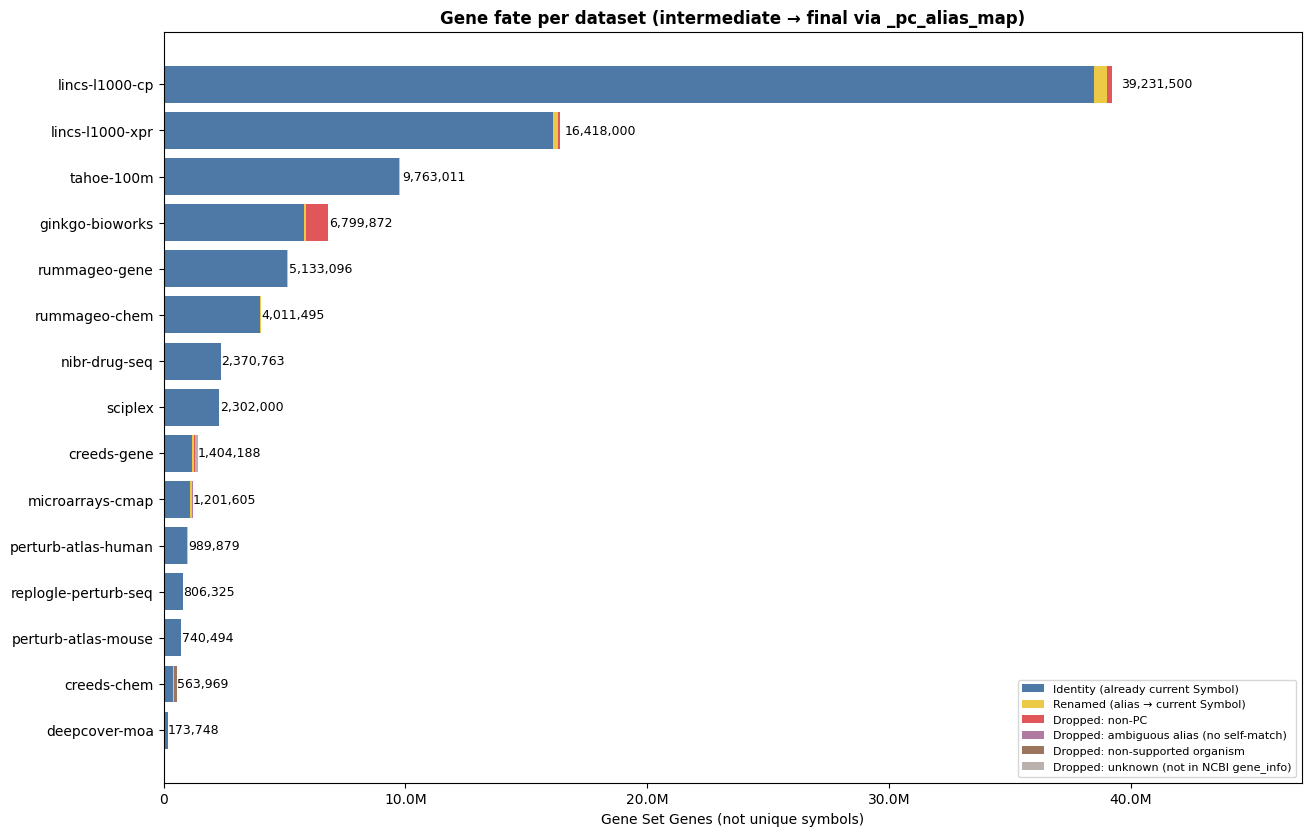

In [104]:
def fmt_count(v):
    return f'{v/1e6:.1f}M' if v >= 1e6 else f'{v/1e3:.0f}k' if v >= 1e3 else str(v)

SEGMENTS = [
    ('identity',        '#4e79a7', 'Identity (already current Symbol)'),
    ('renamed',         '#edc948', 'Renamed (alias → current Symbol)'),
    ('drop_non_pc',     '#e15759', 'Dropped: non-PC'),
    ('drop_ambiguous',  '#b07aa1', 'Dropped: ambiguous alias (no self-match)'),
    ('drop_unsupp_org', '#9c755f', 'Dropped: non-supported organism'),
    ('drop_unknown',    '#bab0ac', 'Dropped: unknown (not in NCBI gene_info)'),
]

def plot_fate(sub, title):
    names = list(sub.sort_values('total_gene_set_genes').index)
    totals = sub.loc[names, 'total_gene_set_genes'].tolist()
    fig, ax = plt.subplots(figsize=(13, max(4, 0.55 * len(names))), constrained_layout=True)
    left = [0] * len(names)
    for col, color, label in SEGMENTS:
        vals = sub.loc[names, col].tolist()
        ax.barh(names, vals, left=left, color=color, label=label)
        left = [l + v for l, v in zip(left, vals)]
    for i, t in enumerate(totals):
        ax.text(t * 1.01, i, f'{t:,}', va='center', fontsize=9)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: fmt_count(int(x))))
    ax.set_xlabel('Gene Set Genes (not unique symbols)')
    ax.set_title(title, fontweight='bold')
    ax.legend(loc='lower right', fontsize=8)
    ax.set_xlim(0, max(totals) * 1.20 if totals else 1)
    plt.show()

_plot_df = df[df['total_gene_set_genes'] > 0]
plot_fate(_plot_df, 'Gene fate per dataset (intermediate → final via _pc_alias_map)')

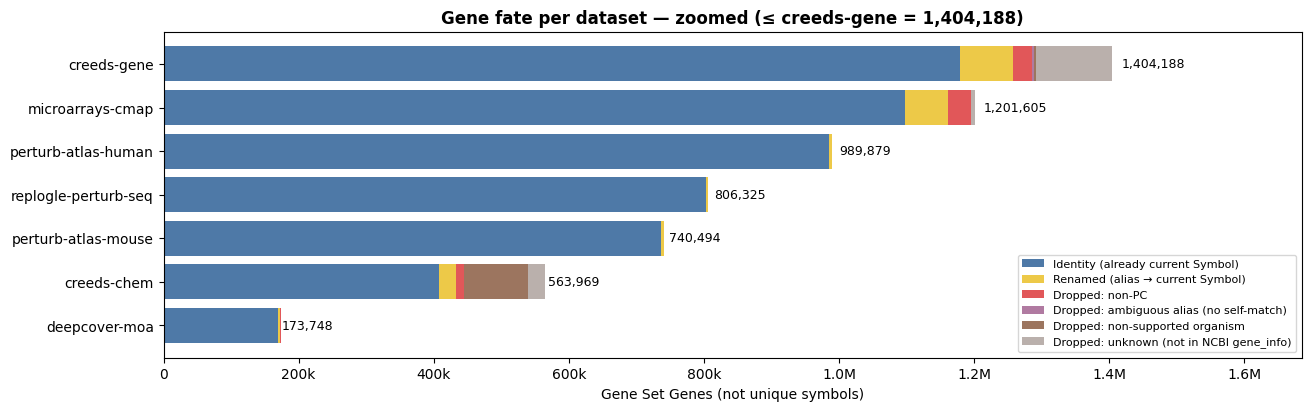

In [105]:
cutoff = _plot_df.loc['creeds-gene', 'total_gene_set_genes']
plot_fate(_plot_df[_plot_df['total_gene_set_genes'] <= cutoff],
          f'Gene fate per dataset — zoomed (≤ creeds-gene = {cutoff:,})')

## Signature count: intermediate vs final

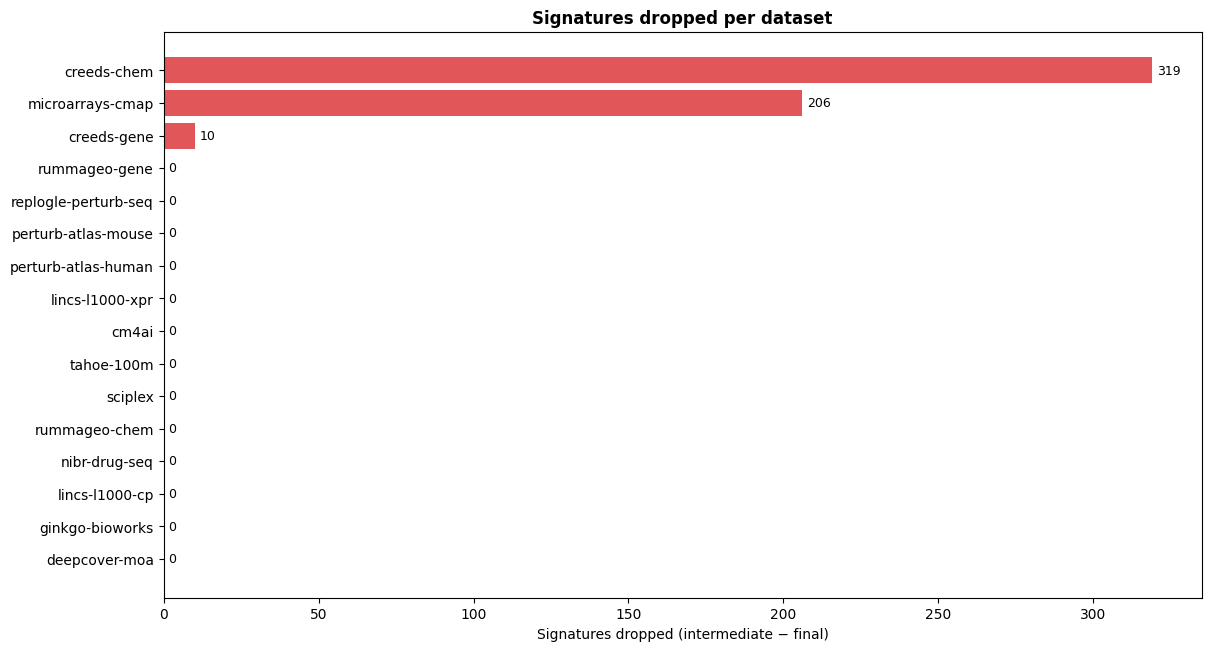

In [106]:
dropped = (df['inter_sigs'] - df['final_sigs']).sort_values()
fig, ax = plt.subplots(figsize=(12, max(4, 0.4 * len(dropped))), constrained_layout=True)
ax.barh(dropped.index, dropped.values, color='#e15759')
for i, v in enumerate(dropped.values):
    ax.text(v + dropped.max() * 0.005, i, f'{v:,}', va='center', fontsize=9)
ax.set_xlabel('Signatures dropped (intermediate − final)')
ax.set_title('Signatures dropped per dataset', fontweight='bold')
plt.show()

## Gene type composition: intermediate vs final

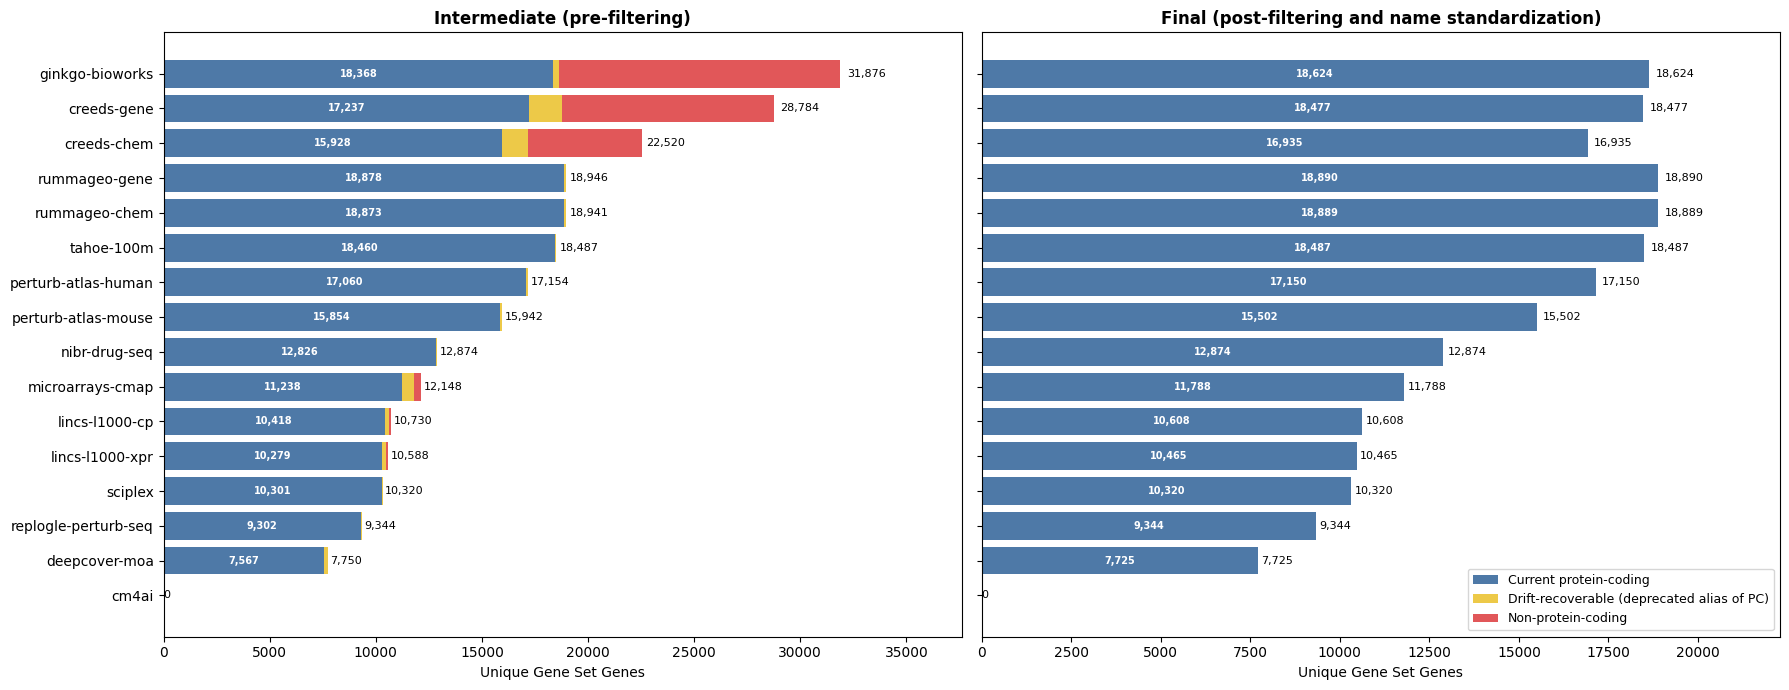

In [107]:
pc_current = set(lookup.values())
pc_alias = set(lookup) - pc_current

def gene_types(path):
    with gzip.open(path, 'rt') as f:
        genes = {g.strip().upper() for line in f if line.strip()
                 for g in line.split('\t')[2:] if g.strip()}
    pc = sum(g in pc_current for g in genes)
    drift = sum(g in pc_alias for g in genes)
    return pc, drift, len(genes) - pc - drift

inter_counts = {name: gene_types(p) for _, name, p, _ in DATASETS if p.exists()}
final_counts = {name: gene_types(p) for _, name, _, p in DATASETS if p.exists()}

names_g = sorted(set(inter_counts) & set(final_counts), key=lambda n: sum(inter_counts[n]))
COLORS = [('#4e79a7', 'Current protein-coding'),
          ('#edc948', 'Drift-recoverable (deprecated alias of PC)'),
          ('#e15759', 'Non-protein-coding')]

fig, axes = plt.subplots(1, 2, figsize=(18, 7), sharey=True)
for ax, counts, title in zip(axes,
        [inter_counts, final_counts],
        ['Intermediate (pre-filtering)', 'Final (post-filtering and name standardization)']):
    segs = [[counts[n][i] for n in names_g] for i in range(3)]
    totals = [sum(counts[n]) for n in names_g]
    min_label = max(totals) // 80 if totals else 1
    left = [0] * len(names_g)
    for i, (vals, (color, label)) in enumerate(zip(segs, COLORS)):
        ax.barh(names_g, vals, left=left, color=color, label=label)
        if i == 0:
            for j, v in enumerate(vals):
                if v >= min_label:
                    ax.text(left[j] + v / 2, j, f'{v:,}', ha='center', va='center',
                            color='white', fontsize=7, fontweight='bold')
        left = [l + v for l, v in zip(left, vals)]
    for j, t in enumerate(totals):
        ax.text(t * 1.01, j, f'{t:,}', va='center', fontsize=8)
    ax.set_xlabel('Unique Gene Set Genes')
    ax.set_title(title, fontweight='bold')
    ax.set_xlim(0, max(totals) * 1.18 if totals else 1)

axes[1].legend(loc='lower right', fontsize=9)
plt.tight_layout(); plt.show()

## Top global renames (alias → current Symbol)

Most-frequent rename events across the entire pipeline. DEGs rewritten to its current NCBI official Symbol so that the same gene appears under one consistent name across datasets.

In [108]:
pd.DataFrame(
    [(a, b, n) for (a, b), n in renames_global.most_common(50)],
    columns=['original_alias', 'current_Symbol', 'occurrences'],
).set_index('original_alias')

,current_Symbol,occurrences
original_alias,,
FAM129A,NIBAN1,39241
HIST1H1C,H1-2,31736
METTL7A,TMT1A,31241
HIST1H2AC,H2AC6,27627
H1F0,H1-0,27388
HIST1H2BD,H2BC5,23667
C3ORF14,CEP15,22585
HIST1H2BK,H2BC12,19498
NDUFA4L2,COXFA4L2,17449


## Top dropped genes

These genes appeared in gene sets but couldn't be resolved by `_pc_alias_map`. Reasons:
- Gene isn't in NCBI gene_info (typo, archaic name with no official record)
- Gene is non-protein-coding (lincRNA, pseudogene, miRNA host)
- Gene is an ambiguous alias not rescued by HGNC `prev_symbol` (e.g. `A1`, `ABP-280`)

In [109]:
def drop_reason(g):
    if g in ambiguous_set: return 'ambiguous (alias → multiple genes)'
    if g in non_pc_set:    return 'non-PC'
    return 'unknown (not in NCBI gene_info)'

pd.DataFrame(
    [(g, n, drop_reason(g)) for g, n in drops_global.most_common(50)],
    columns=['dropped_gene', 'occurrences', 'reason'],
).set_index('dropped_gene')

,occurrences,reason
dropped_gene,,
XIST,54559,non-PC
NEAT1,29401,non-PC
GUSBP3,24086,non-PC
CMAHP,18826,non-PC
MIR22HG,16652,non-PC
C6ORF48,15171,non-PC
CYP2B7P,12041,non-PC
FAM30A,10952,non-PC
LINC00623,10199,non-PC


## Ambiguous-alias drops per dataset

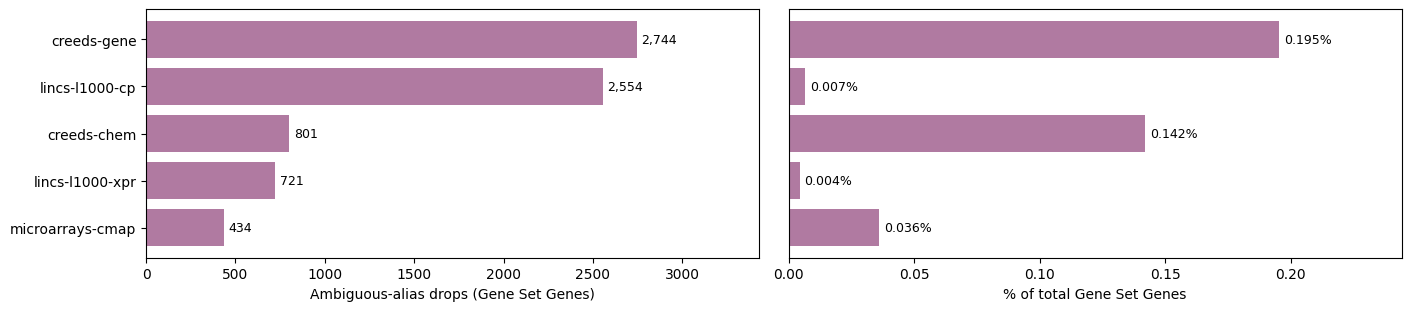

,ambiguous_drops,% of dataset
dataset,,
microarrays-cmap,434,0.036118
lincs-l1000-xpr,721,0.004392
creeds-chem,801,0.142029
lincs-l1000-cp,2554,0.006510
creeds-gene,2744,0.195415


In [110]:
amb = df[df['drop_ambiguous'] > 0].copy()
amb['pct'] = 100 * amb['drop_ambiguous'] / amb['total_gene_set_genes']
amb = amb.sort_values('drop_ambiguous')

fig, axes = plt.subplots(1, 2, figsize=(14, max(3, 0.5 * len(amb))), constrained_layout=True)
for ax, col, xlabel, fmt in [
    (axes[0], 'drop_ambiguous', 'Ambiguous-alias drops (Gene Set Genes)', '{:,}'),
    (axes[1], 'pct',            '% of total Gene Set Genes',              '{:.3f}%'),
]:
    ax.barh(amb.index, amb[col], color='#b07aa1')
    for i, v in enumerate(amb[col]):
        ax.text(v + amb[col].max() * 0.01, i, fmt.format(v), va='center', fontsize=9)
    ax.set_xlabel(xlabel); ax.set_xlim(0, amb[col].max() * 1.25)
axes[1].tick_params(axis='y', left=False, labelleft=False)
plt.show()

amb[['drop_ambiguous', 'pct']].rename(columns={'drop_ambiguous': 'ambiguous_drops', 'pct': '% of dataset'})